# Census Income - Modelling Progression
## Part 4 | Hugo's contribution

**Dataset:** Adult / Census Income, OpenML version 2.

**Question:** after the feature engineering and imbalance analysis, what do more
flexible models improve over logistic regression?

This is an **executed working notebook**: code, checks, tables, charts and
interpretations are visible in the cells. It compares **three learned models**
plus a dummy reference. No test-set model score is computed.

### Built on the group's work

| Existing contribution, reused unchanged | New in this notebook |
|---|---|
| Jérémy: original EDA | Three-model comparison and interpretation |
| Hugo: deduplication and grouped train/validation/test split | Group-aware CV comparisons on the same training folds |
| Yanis, part 2: imputation, fixed category grouping, capital features and encoding | Random forest and histogram gradient boosting |
| Yanis, part 3: `build_pipeline`, `evaluate_model`, `find_best_threshold` | Common metric tables, learning gaps, timing and charts |

Yanis's chosen strategy is retained: **no class weighting**, and a decision
threshold selected on validation by positive-class F1. His logistic threshold
around **0.282 belongs to that model**; each new model needs its own threshold.
The same validation data are used for threshold selection and display, so
threshold-dependent validation results are exploratory and somewhat optimistic.

Prepared with AI assistance. Every model and methodological choice should be
understood and defended by the group. This notebook adds a separate contribution;
it does not replace or edit the teammates' source files.

## 1. Reproducible setup
Run the cells in order in Colab or Jupyter. CPU is sufficient. The notebook uses
the tested pandas/scikit-learn versions. If run outside an existing checkout, it
downloads the exact reviewed repository revision into a separate working folder.
No GitHub credential, upload or automatic commit is required.

In [1]:
import importlib.metadata as metadata
import subprocess
import sys

required = {"pandas": "2.2.3", "scikit-learn": "1.8.0", "matplotlib": "3.10.8"}
install = []
for package, version in required.items():
    try:
        current = metadata.version(package)
    except metadata.PackageNotFoundError:
        current = None
    if current != version:
        install.append(f"{package}=={version}")
try:
    metadata.version("openpyxl")
except metadata.PackageNotFoundError:
    install.append("openpyxl>=3.1")
if install:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *install], check=True)
    print("Packages installed. If a notebook imported another version earlier, restart its runtime first.")
else:
    print("The tested dependencies are already available.")

The tested dependencies are already available.


In [2]:
from pathlib import Path
import hashlib
import json
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

assert metadata.version("scikit-learn") == "1.8.0"
SEED = 42
N_FOLDS = 5
THREADS = 2
METRICS = ["average_precision", "roc_auc", "precision", "recall", "f1", "accuracy"]
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
print({package: metadata.version(package) for package in ["numpy", "pandas", "scikit-learn", "matplotlib"]})

No event loop hook running.
{'numpy': '2.3.5', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.8'}


In [3]:
SOURCE_COMMIT = '3aafb1a9512fc956af13ce3e29d4f80bff7ad313'
SOURCE_HASHES = {
    "census_income.xlsx": "906e9b20a215aabae985e861c65a2e42ff896ec41c0702d34e308eb0f7f19d50",
    "contributions/hugo/eda_and_data_splitting/src/prepare_data.py": "222cf32dd7454ddf7c94602369afbd4329a1d16e4c4250b9ca589bc1e715b6e6",
    "contributions/yanis/feature_engineering/src/build_features.py": "050b87b05c3515d87ab4f7a31a1fd447cfeb7126c05fb3f37baa98d4b313b8b1",
    "contributions/yanis/class_imbalance/src/compare_imbalance.py": "2da960167b023b651e2df4dfc03ec54bf6074cda235122a8221df98b0e74fa51",
    "contributions/yanis/class_imbalance/src/evaluate.py": "cba30384a552eaf7f472c5fdbef9723a1727a316c1dce0b69cac3270da7d1f09"
}
REPO_URL = "https://github.com/CLDprog/Supervised-Learning-Census-Income-.git"

def locate_project():
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "contributions/yanis/class_imbalance/src/evaluate.py").exists():
            return candidate
    candidate = Path("/content/census_model_comparison_source")
    if not candidate.exists():
        candidate.parent.mkdir(parents=True, exist_ok=True)
        subprocess.run(["git", "clone", "--no-checkout", "--depth", "1", REPO_URL, str(candidate)], check=True)
        subprocess.run(["git", "fetch", "--depth", "1", "origin", SOURCE_COMMIT], cwd=candidate, check=True)
        subprocess.run(["git", "checkout", "--detach", SOURCE_COMMIT], cwd=candidate, check=True)
    return candidate

ROOT = locate_project()
for relative, expected in SOURCE_HASHES.items():
    actual = hashlib.sha256((ROOT / relative).read_bytes()).hexdigest()
    if actual != expected:
        raise RuntimeError(f"Reviewed dependency changed: {relative}. Review it before rerunning this comparison.")
sys.path.insert(0, str(ROOT))
OUTPUT_DIR = ROOT / "contributions/hugo/model_comparison/outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
tracked = subprocess.check_output(["git", "ls-files"], cwd=ROOT, text=True).splitlines()
PROTECTED = {p: hashlib.sha256((ROOT / p).read_bytes()).hexdigest()
             for p in tracked if not p.startswith("contributions/hugo/model_comparison/")}
print("Reviewed revision:", SOURCE_COMMIT)
print("Project:", ROOT)
print("Existing source files are reused, not rewritten.")

Reviewed revision: 3aafb1a9512fc956af13ce3e29d4f80bff7ad313
Project: /workspace/scratch/2d9f2ecf909e/census-model-comparison
Existing source files are reused, not rewritten.


## 2. Reuse the existing data split and Yanis's functions

The original split has 34,156 / 7,317 / 7,317 observations. Five pairs have
identical original predictors but opposite labels, and are kept in the same
partition. Missing generated CSVs are recreated using Hugo's existing code.
This performs structural checks on all partitions; **test labels/probabilities
are not loaded for model fitting, threshold selection or performance reporting**.

Only the training and validation partitions are subsequently read. The target
is `1 = >50K`. The 11 raw predictors and the 50 encoded features follow part 2.
`sex` is kept separately for the later fairness audit.

In [4]:
from contributions.hugo.eda_and_data_splitting.src.prepare_data import (
    load_raw, export_splits, load_partition, model_inputs, ROW_ID, TARGET,
)
from contributions.yanis.class_imbalance.src.compare_imbalance import build_pipeline
from contributions.yanis.class_imbalance.src.evaluate import evaluate_model, find_best_threshold
from contributions.yanis.feature_engineering.src.build_features import DATA_DIR

if not (DATA_DIR / "manifest.json").exists():
    export_splits(load_raw(ROOT / "census_income.xlsx"), DATA_DIR, "repository census_income.xlsx", SEED)
manifest = json.loads((DATA_DIR / "manifest.json").read_text())
access_log = []
def development_partition(name):
    if name not in {"train", "validation"}:
        raise ValueError("The final test partition is intentionally unavailable in part 4.")
    access_log.append(name)
    return load_partition(DATA_DIR, name)

train_df = development_partition("train")
validation_df = development_partition("validation")
X_train, y_train, sex_train = model_inputs(train_df)
X_val, y_val, sex_val = model_inputs(validation_df)
assert X_train.shape == (34156, 11)
assert X_val.shape == (7317, 11)
assert int(y_val.sum()) == 1752
assert X_train.index.intersection(X_val.index).empty
assert X_train.index.equals(y_train.index) and X_train.index.equals(sex_train.index)
assert not {"sex", "class", "row_id", "fnlwgt", "education"}.intersection(X_train.columns)
display(pd.DataFrame([
    {"partition": "train", "rows": len(y_train), "positive_count": int(y_train.sum()), "positive_rate": y_train.mean()},
    {"partition": "validation", "rows": len(y_val), "positive_count": int(y_val.sum()), "positive_rate": y_val.mean()},
]).set_index("partition"))
print("Model-comparison access log:", access_log)

Model-comparison access log: ['train', 'validation']


,rows,positive_count,positive_rate
partition,,,
train,34156,8177,0.239402
validation,7317,1752,0.239442


### Preprocessing is identical for the three models

Reuse Yanis's complete pipeline: constant imputation → fixed category grouping
→ capital features → scaling/one-hot encoding → classifier. Every fitted
transformer is refitted inside each CV training fold. The only representation
adjustment is **dense output for all models**, because histogram gradient
boosting requires it. Roughly 50 columns make this manageable here.

The missing-value label `Unemployed` is an inherited modelling assumption, not
verified employment status. The `capital_gain_capped` indicator is retained as
part of the shared features; its coding interpretation requires source checks.
Using a common preprocessing recipe isolates the comparison within this recipe;
it does not establish that this recipe is optimal for every model.

In [5]:
def comparison_pipeline(estimator):
    pipeline = build_pipeline(clone(estimator))
    pipeline.set_params(encode__sparse_threshold=0.0)
    return pipeline

# Inspect the recipe without fitting anything yet.
display(comparison_pipeline(LogisticRegression(max_iter=1000, random_state=SEED)))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('impute', ...), ('group_rare', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('workclass_occupation', ...), ('native_country', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the 

## 3. Three learned models, with fixed initial settings

| Step | Model | What it can add | Main limitation |
|---|---|---|---|
| 1 | Logistic regression | Reproduce Yanis's linear baseline on log-odds | Interactions are not learned automatically |
| 2 | Random forest | Nonlinear splits and interactions; averaging reduces individual-tree variance | More training cost and potential overfitting |
| 3 | Histogram gradient boosting | Sequential additive trees refine residual errors | Sensitive to iteration/complexity choices; calibration still needs checking |

A majority-class **DummyClassifier is a reference, not one of the three learned
models**. Presets below are fixed before observing these results. There is no
hyperparameter search in part 4; Optuna is reserved for part 6. Higher complexity
does not guarantee improvement: the executed comparison decides what is useful.

All learned models use **no class weighting**, following part 3. Each later
receives its own validation-selected F1 threshold. Do not assume that unweighted
model probabilities are calibrated: part 9 must check this.

In [6]:
estimators = {
    "Logistic regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Random forest": RandomForestClassifier(
        n_estimators=200, max_features="sqrt", min_samples_leaf=2,
        class_weight=None, random_state=SEED, n_jobs=THREADS,
    ),
    "Histogram gradient boosting": HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.1, max_leaf_nodes=31,
        min_samples_leaf=20, early_stopping=False,
        class_weight=None, random_state=SEED,
    ),
}
dummy_estimator = DummyClassifier(strategy="most_frequent")
display(pd.DataFrame({name: model.get_params() for name, model in estimators.items()}).fillna("-"))

,Logistic regression,Random forest,Histogram gradient boosting
C,1.0,-,-
class_weight,-,-,-
dual,False,-,-
fit_intercept,True,-,-
intercept_scaling,1,-,-
l1_ratio,0.0,-,-
max_iter,1000,-,200
n_jobs,-,2,-
penalty,deprecated,-,-
random_state,42,42,42


## 4. Group-aware five-fold CV on training only

Use the **same five folds for every candidate**, with `StratifiedGroupKFold`
and seed 42. Group by the complete original predictor profile, including the
survey weight, to keep the previously identified pairs together inside CV too.
This deliberately strengthens part 3's row-stratified CV without modifying it.
Therefore its CV averages need not exactly match Yanis's published averages.

The primary comparison is **mean training-CV Average Precision**. Precision,
recall, F1, accuracy and confusion counts use a common threshold of 0.50 during
CV. Standard deviations describe variation across five folds; they are not
confidence intervals or independent hypothesis tests.

In [7]:
profile_columns = [c for c in train_df.columns if c not in {ROW_ID, TARGET}]
cv_groups = pd.util.hash_pandas_object(train_df[profile_columns], index=False).to_numpy()
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train, cv_groups))
fold_audit = []
for fold, (fit_indices, score_indices) in enumerate(folds, 1):
    assert set(cv_groups[fit_indices]).isdisjoint(set(cv_groups[score_indices]))
    assert set(fit_indices).isdisjoint(set(score_indices))
    fold_audit.append({
        "fold": fold, "fit_rows": len(fit_indices), "score_rows": len(score_indices),
        "score_positive_rate": y_train.iloc[score_indices].mean(),
    })
assert sorted(np.concatenate([score for _, score in folds]).tolist()) == list(range(len(X_train)))
display(pd.DataFrame(fold_audit).set_index("fold"))
print("Checks passed: each training row is scored once; original-profile groups never cross a CV fold boundary.")

Checks passed: each training row is scored once; original-profile groups never cross a CV fold boundary.


,fit_rows,score_rows,score_positive_rate
fold,,,
1,27325,6831,0.239496
2,27324,6832,0.239461
3,27325,6831,0.239350
4,27325,6831,0.239350
5,27325,6831,0.239350


In [8]:
cv_records = []
fitted_models = {}
val_probabilities = {}
full_fit_seconds = {}
train_average_precision = {}

def compare_candidate(name, estimator):
    print(name)
    for fold, (fit_indices, score_indices) in enumerate(folds, 1):
        candidate = comparison_pipeline(estimator)
        started = time.perf_counter()
        with warnings.catch_warnings(record=True) as captured, threadpool_limits(limits=THREADS):
            warnings.simplefilter("always", ConvergenceWarning)
            candidate.fit(X_train.iloc[fit_indices], y_train.iloc[fit_indices])
            elapsed = time.perf_counter() - started
            proba = candidate.predict_proba(X_train.iloc[score_indices])[:, 1]
        convergence = [str(w.message) for w in captured if issubclass(w.category, ConvergenceWarning)]
        if convergence:
            raise RuntimeError(f"Unresolved convergence warning in {name}, fold {fold}: {convergence}")
        scores = evaluate_model(y_train.iloc[score_indices], proba, threshold=0.5)
        cv_records.append({"model": name, "fold": fold, "fit_seconds": elapsed, **scores})
        print(f"  fold {fold}: AP={scores['average_precision']:.4f}, ROC-AUC={scores['roc_auc']:.4f}")
    full_model = comparison_pipeline(estimator)
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as captured, threadpool_limits(limits=THREADS):
        warnings.simplefilter("always", ConvergenceWarning)
        full_model.fit(X_train, y_train)
        full_fit_seconds[name] = time.perf_counter() - started
        val_probabilities[name] = full_model.predict_proba(X_val)[:, 1]
        train_score = full_model.predict_proba(X_train)[:, 1]
    if any(issubclass(w.category, ConvergenceWarning) for w in captured):
        raise RuntimeError(f"Unresolved convergence warning in full {name}")
    fitted_models[name] = full_model
    train_average_precision[name] = average_precision_score(y_train, train_score)
    print(f"  full training fit: {full_fit_seconds[name]:.2f}s; validation AP={average_precision_score(y_val, val_probabilities[name]):.4f}")

### 4A. Logistic regression - reproduce the part 3 baseline

In [9]:
compare_candidate("Logistic regression", estimators["Logistic regression"])

Logistic regression
  fold 1: AP=0.7380, ROC-AUC=0.9009
  fold 2: AP=0.7213, ROC-AUC=0.8928
  fold 3: AP=0.7412, ROC-AUC=0.8988
  fold 4: AP=0.7451, ROC-AUC=0.8985
  fold 5: AP=0.7390, ROC-AUC=0.8999
  full training fit: 0.19s; validation AP=0.7416


### 4B. Random forest - nonlinear interactions and averaging

In [10]:
compare_candidate("Random forest", estimators["Random forest"])

Random forest
  fold 1: AP=0.8033, ROC-AUC=0.9179
  fold 2: AP=0.8009, ROC-AUC=0.9136
  fold 3: AP=0.8042, ROC-AUC=0.9171
  fold 4: AP=0.8053, ROC-AUC=0.9167
  fold 5: AP=0.8080, ROC-AUC=0.9198
  full training fit: 2.27s; validation AP=0.8088


### 4C. Histogram gradient boosting - sequential tree refinement

In [11]:
compare_candidate("Histogram gradient boosting", estimators["Histogram gradient boosting"])

Histogram gradient boosting
  fold 1: AP=0.8238, ROC-AUC=0.9278
  fold 2: AP=0.8195, ROC-AUC=0.9225
  fold 3: AP=0.8252, ROC-AUC=0.9260
  fold 4: AP=0.8246, ROC-AUC=0.9254
  fold 5: AP=0.8273, ROC-AUC=0.9306
  full training fit: 1.41s; validation AP=0.8306


### Dummy reference - the majority-class prediction

In [12]:
compare_candidate("Dummy: majority class", dummy_estimator)

Dummy: majority class
  fold 1: AP=0.2395, ROC-AUC=0.5000
  fold 2: AP=0.2395, ROC-AUC=0.5000
  fold 3: AP=0.2394, ROC-AUC=0.5000
  fold 4: AP=0.2394, ROC-AUC=0.5000
  fold 5: AP=0.2394, ROC-AUC=0.5000
  full training fit: 0.05s; validation AP=0.2394


## 5. The same CV metrics for every model
AP and ROC-AUC use probability scores. Threshold-dependent CV metrics use 0.50
for everyone. The dummy is shown separately as a reference. No model is selected
using its training resubstitution score or its threshold-optimized validation F1.

In [13]:
cv_results = pd.DataFrame(cv_records)
cv_mean = cv_results.groupby("model")[METRICS + ["fit_seconds"]].mean()
cv_sd = cv_results.groupby("model")[METRICS].std(ddof=1)
candidate_names = list(estimators)
order = candidate_names + ["Dummy: majority class"]
cv_table = pd.DataFrame(index=order)
for metric in METRICS:
    cv_table[metric] = [f"{cv_mean.loc[name, metric]:.4f} ± {cv_sd.loc[name, metric]:.4f}" for name in order]
cv_table["mean_fold_fit_seconds"] = cv_mean.loc[order, "fit_seconds"].round(2)
display(cv_table)

# Primary, predeclared ranking: training CV AP, among the three learned models.
selected_candidate = cv_mean.loc[candidate_names, "average_precision"].idxmax()
print("Candidate to carry forward, based on training CV AP:", selected_candidate)
print("This is a part-4 candidate, not a tuned or final test-validated model.")

Candidate to carry forward, based on training CV AP: Histogram gradient boosting
This is a part-4 candidate, not a tuned or final test-validated model.


,average_precision,roc_auc,precision,recall,f1,accuracy,mean_fold_fit_seconds
Logistic regression,0.7369 ± 0.0091,0.8982 ± 0.0032,0.7141 ± 0.0157,0.5830 ± 0.0108,0.6419 ± 0.0107,0.8442 ± 0.0051,0.15
Random forest,0.8044 ± 0.0026,0.9170 ± 0.0022,0.7665 ± 0.0060,0.6210 ± 0.0106,0.6861 ± 0.0074,0.8640 ± 0.0026,1.66
Histogram gradient boosting,0.8241 ± 0.0029,0.9264 ± 0.0030,0.7722 ± 0.0044,0.6506 ± 0.0129,0.7062 ± 0.0083,0.8704 ± 0.0028,1.31
Dummy: majority class,0.2394 ± 0.0001,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.7606 ± 0.0001,0.04


## 6. Validation - default and model-specific thresholds

First compare every model at **0.50**. Next apply Yanis's `find_best_threshold`
separately to each learned model, using validation only. Keep the dummy fixed as
majority prediction. Display all the same metrics and confusion counts.

The selected thresholds are measured on the data used to select them; the F1
values in the second table are **not unbiased final performance estimates**.
Changing the threshold affects class predictions, not AP or ROC-AUC.

In [14]:
default_rows, selected_rows = [], []
thresholds = {}
for name in order:
    probabilities = val_probabilities[name]
    default_rows.append({"model": name, "threshold": 0.5, **evaluate_model(y_val, probabilities, 0.5)})
    threshold = find_best_threshold(y_val, probabilities) if name in estimators else 0.5
    thresholds[name] = float(threshold)
    selected_rows.append({"model": name, "threshold": threshold, **evaluate_model(y_val, probabilities, threshold)})
default_results = pd.DataFrame(default_rows).set_index("model")
threshold_results = pd.DataFrame(selected_rows).set_index("model")
display(Markdown("### Validation at the common threshold 0.50"))
display(default_results.round(4))
display(Markdown("### Exploratory validation at selected F1 thresholds"))
display(threshold_results.round(4))
print("Logistic threshold to compare with Yanis's approximately 0.282:", round(thresholds["Logistic regression"], 6))

Logistic threshold to compare with Yanis's approximately 0.282: 0.28191


### Validation at the common threshold 0.50

,threshold,average_precision,roc_auc,precision,recall,f1,accuracy,tn,fp,fn,tp
model,,,,,,,,,,,
Logistic regression,0.5,0.7416,0.9002,0.7195,0.5856,0.6457,0.8461,5165,400,726,1026
Random forest,0.5,0.8088,0.9175,0.7704,0.6261,0.6908,0.8658,5238,327,655,1097
Histogram gradient boosting,0.5,0.8306,0.9272,0.7826,0.6535,0.7123,0.8736,5247,318,607,1145
Dummy: majority class,0.5,0.2394,0.5000,0.0000,0.0000,0.0000,0.7606,5565,0,1752,0


### Exploratory validation at selected F1 thresholds

,threshold,average_precision,roc_auc,precision,recall,f1,accuracy,tn,fp,fn,tp
model,,,,,,,,,,,
Logistic regression,0.2819,0.7416,0.9002,0.5898,0.8116,0.6832,0.8197,4576,989,330,1422
Random forest,0.4347,0.8088,0.9175,0.7343,0.7003,0.7169,0.8676,5121,444,525,1227
Histogram gradient boosting,0.4046,0.8306,0.9272,0.7205,0.7414,0.7308,0.8692,5061,504,453,1299
Dummy: majority class,0.5000,0.2394,0.5000,0.0000,0.0000,0.0000,0.7606,5565,0,1752,0


## 7. What did each step buy us?

Use AP gains, recall/precision changes, the train-to-CV gap and training cost.
The train score is an optimistic resubstitution diagnostic. Subtracting the CV
AP from it indicates possible overfitting, not an unbiased measure of optimism.
Timing comes from this runtime, with two threads; it is not a hardware-independent
benchmark. Baseline hyperparameters differ across model families, so observed
gains concern these complete configurations, not a controlled causal effect of
one architectural feature.

In [15]:
progression_rows = []
previous_cv = None
for name in candidate_names:
    current_ap = cv_mean.loc[name, "average_precision"]
    progression_rows.append({
        "model": name,
        "training_AP": train_average_precision[name],
        "CV_AP": current_ap,
        "CV_AP_SD": cv_sd.loc[name, "average_precision"],
        "AP_gain_vs_previous_step": np.nan if previous_cv is None else current_ap - previous_cv,
        "train_minus_CV_AP": train_average_precision[name] - current_ap,
        "validation_AP": threshold_results.loc[name, "average_precision"],
        "validation_F1_selected_threshold": threshold_results.loc[name, "f1"],
        "full_fit_seconds": full_fit_seconds[name],
    })
    previous_cv = current_ap
progression = pd.DataFrame(progression_rows).set_index("model")
display(progression.round(4))

,training_AP,CV_AP,CV_AP_SD,AP_gain_vs_previous_step,train_minus_CV_AP,validation_AP,validation_F1_selected_threshold,full_fit_seconds
model,,,,,,,,
Logistic regression,0.7385,0.7369,0.0091,NaN,0.0016,0.7416,0.6832,0.1932
Random forest,0.9117,0.8044,0.0026,0.0674,0.1074,0.8088,0.7169,2.2748
Histogram gradient boosting,0.8726,0.8241,0.0029,0.0197,0.0486,0.8306,0.7308,1.4135


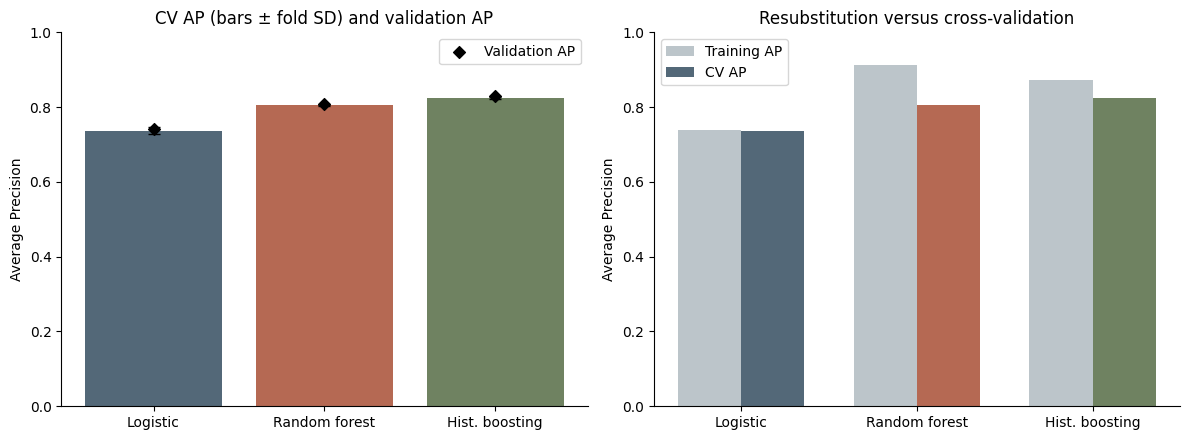

In [16]:
COLORS = ["#536878", "#B56953", "#6F8261"]
FIGURES = []
def show_save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / name, dpi=150, bbox_inches="tight")
    FIGURES.append(name)
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(3)
axes[0].bar(x, cv_mean.loc[candidate_names, "average_precision"], yerr=cv_sd.loc[candidate_names, "average_precision"], color=COLORS, capsize=4)
axes[0].scatter(x, threshold_results.loc[candidate_names, "average_precision"], marker="D", color="black", label="Validation AP")
axes[0].set_xticks(x, ["Logistic", "Random forest", "Hist. boosting"])
axes[0].set(title="CV AP (bars ± fold SD) and validation AP", ylabel="Average Precision", ylim=(0, 1))
axes[0].legend()
axes[1].bar(x - 0.18, [train_average_precision[n] for n in candidate_names], width=0.36, label="Training AP", color="#BCC5CA")
axes[1].bar(x + 0.18, cv_mean.loc[candidate_names, "average_precision"], width=0.36, label="CV AP", color=COLORS)
axes[1].set_xticks(x, ["Logistic", "Random forest", "Hist. boosting"])
axes[1].set(title="Resubstitution versus cross-validation", ylabel="Average Precision", ylim=(0, 1))
axes[1].legend()
show_save(fig, "01_model_progression.png")

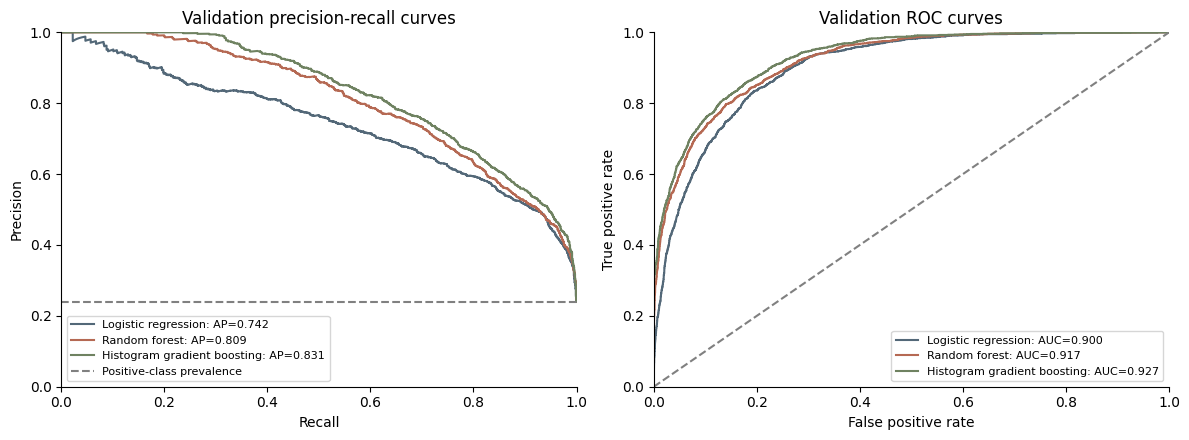

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, color in zip(candidate_names, COLORS):
    precision, recall, _ = precision_recall_curve(y_val, val_probabilities[name])
    axes[0].plot(recall, precision, color=color, label=f"{name}: AP={threshold_results.loc[name, 'average_precision']:.3f}")
    fpr, tpr, _ = roc_curve(y_val, val_probabilities[name])
    axes[1].plot(fpr, tpr, color=color, label=f"{name}: AUC={threshold_results.loc[name, 'roc_auc']:.3f}")
axes[0].axhline(y_val.mean(), color="grey", linestyle="--", label="Positive-class prevalence")
axes[0].set(title="Validation precision-recall curves", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--")
axes[1].set(title="Validation ROC curves", xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1))
for ax in axes: ax.legend(fontsize=8)
show_save(fig, "02_validation_curves.png")

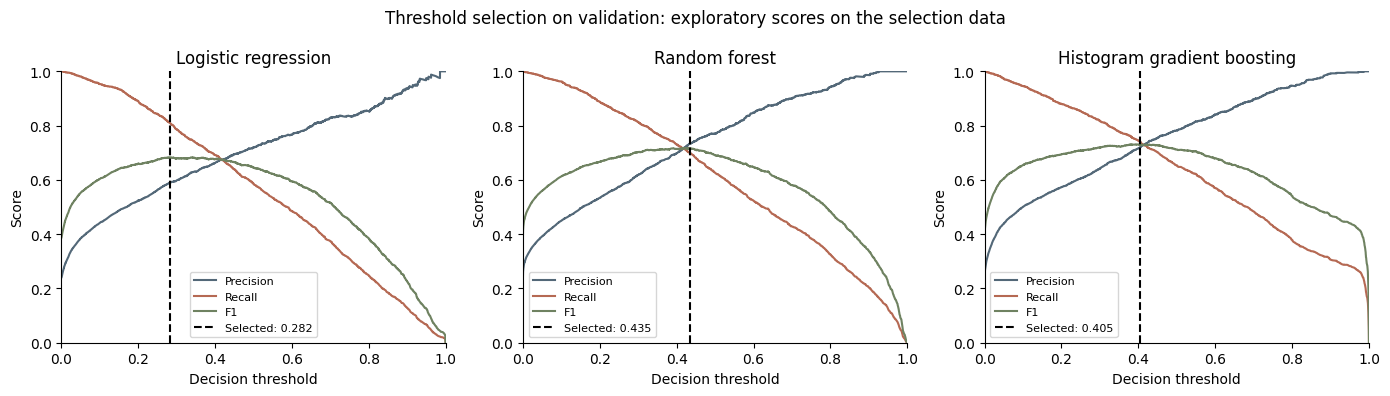

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for name, ax in zip(candidate_names, axes):
    precision, recall, grid = precision_recall_curve(y_val, val_probabilities[name])
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    ax.plot(grid, precision[:-1], label="Precision", color=COLORS[0])
    ax.plot(grid, recall[:-1], label="Recall", color=COLORS[1])
    ax.plot(grid, f1, label="F1", color=COLORS[2])
    ax.axvline(thresholds[name], color="black", linestyle="--", label=f"Selected: {thresholds[name]:.3f}")
    ax.set(title=name, xlabel="Decision threshold", ylabel="Score", xlim=(0, 1), ylim=(0, 1))
    ax.legend(fontsize=8)
fig.suptitle("Threshold selection on validation: exploratory scores on the selection data")
show_save(fig, "03_threshold_tradeoffs.png")

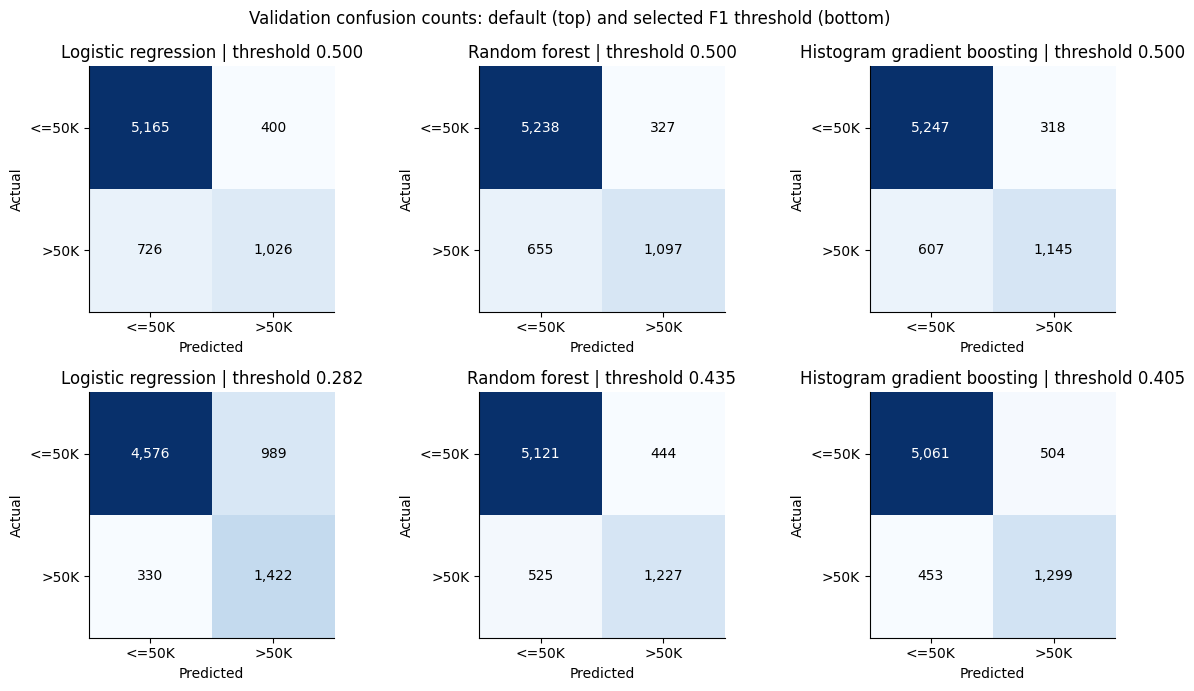

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for column, name in enumerate(candidate_names):
    for row, results in enumerate([default_results, threshold_results]):
        r = results.loc[name]
        counts = np.array([[r.tn, r.fp], [r.fn, r.tp]], dtype=int)
        ax = axes[row, column]
        ax.imshow(counts, cmap="Blues")
        for (i, j), count in np.ndenumerate(counts):
            ax.text(j, i, f"{count:,}", ha="center", va="center", color="white" if count > counts.max() / 2 else "black")
        ax.set_xticks([0, 1], ["<=50K", ">50K"])
        ax.set_yticks([0, 1], ["<=50K", ">50K"])
        ax.set(title=f"{name} | threshold {r.threshold:.3f}", xlabel="Predicted", ylabel="Actual")
fig.suptitle("Validation confusion counts: default (top) and selected F1 threshold (bottom)")
show_save(fig, "04_validation_confusion_matrices.png")

## 8. Executed integrity and consistency checks

These checks verify comparability and score calculations, not unseen-data
performance or fairness. They include the teammates' existing automated tests.
No test labels are used for threshold selection, and no final test score is
produced. The third-party source files remain unchanged.

In [20]:
checks = []
assert len(cv_results) == 4 * N_FOLDS
checks.append("4 candidates evaluated on exactly the same 5 CV folds")
assert cv_results.groupby("model").fold.nunique().eq(5).all()
assert access_log == ["train", "validation"]
checks.append("Only train and validation loaded for model comparison")
for name in order:
    p = val_probabilities[name]
    assert p.shape == y_val.shape and np.isfinite(p).all()
    assert ((0 <= p) & (p <= 1)).all()
    assert int(threshold_results.loc[name, ["tn", "fp", "fn", "tp"]].sum()) == len(y_val)
    np.testing.assert_allclose(default_results.loc[name, ["average_precision", "roc_auc"]].astype(float), threshold_results.loc[name, ["average_precision", "roc_auc"]].astype(float))
    if name in estimators:
        assert threshold_results.loc[name, "f1"] >= default_results.loc[name, "f1"] - 1e-12
    transformed = fitted_models[name][:-1].transform(X_val.iloc[:3])
    assert isinstance(transformed, np.ndarray) and transformed.shape == (3, 50)
    assert np.isfinite(transformed.astype(float)).all()
    assert fitted_models[name].named_steps["impute"].feature_names_in_.tolist() == X_train.columns.tolist()
checks.extend(["50 dense features for all models", "Finite probabilities and valid confusion counts", "AP/ROC-AUC invariant to threshold changes", "Selected validation F1 is no lower than default F1"])
assert default_results.loc["Dummy: majority class", "recall"] == 0
assert default_results.loc["Dummy: majority class", "accuracy"] > 0.75
checks.append("Majority baseline exposes the accuracy trap")
for relative, expected in PROTECTED.items():
    assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == expected, relative
checks.append("All existing tracked group files are unchanged")
for check in checks:
    print("PASS:", check)
print(f"{len(checks)} notebook integrity checks passed.")

PASS: 4 candidates evaluated on exactly the same 5 CV folds
PASS: Only train and validation loaded for model comparison
PASS: 50 dense features for all models
PASS: Finite probabilities and valid confusion counts
PASS: AP/ROC-AUC invariant to threshold changes
PASS: Selected validation F1 is no lower than default F1
PASS: Majority baseline exposes the accuracy trap
PASS: All existing tracked group files are unchanged
8 notebook integrity checks passed.


In [21]:
test_suites = [
    "contributions/yanis/feature_engineering/tests",
    "contributions/yanis/class_imbalance/tests",
]
for suite in test_suites:
    result = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", suite, "-v"], cwd=ROOT, text=True, capture_output=True)
    print(result.stdout)
    print(result.stderr)
    if result.returncode:
        raise RuntimeError(f"Existing test suite failed: {suite}")
print("Yanis's 5 feature-engineering tests and 4 imbalance tests pass unchanged.")


test_capital_gain_capped_matches_raw_value (test_feature.TestFeatureEngineering.test_capital_gain_capped_matches_raw_value) ... ok
test_native_country_has_three_categories (test_feature.TestFeatureEngineering.test_native_country_has_three_categories) ... ok
test_no_missing_values_after_imputation (test_feature.TestFeatureEngineering.test_no_missing_values_after_imputation) ... ok
test_rare_workclass_categories_are_grouped (test_feature.TestFeatureEngineering.test_rare_workclass_categories_are_grouped) ... ok
test_validation_produces_same_column_count_as_train (test_feature.TestFeatureEngineering.test_validation_produces_same_column_count_as_train) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.160s

OK


test_best_threshold_on_perfectly_separated_example (test_class_imbalance.TestEvaluateModel.test_best_threshold_on_perfectly_separated_example) ... ok
test_metrics_match_hand_calculation (test_class_imbalance.TestEvaluateModel.test_metri

## 9. Evidence-based interpretation
The following summary is generated from the executed results. Validation
threshold scores remain exploratory; no claim about final test performance,
probability calibration or model fairness is made here.

In [22]:
lr, rf, hgb = candidate_names
cv_gain_rf = progression.loc[rf, "CV_AP"] - progression.loc[lr, "CV_AP"]
cv_gain_hgb = progression.loc[hgb, "CV_AP"] - progression.loc[rf, "CV_AP"]
baseline_val_f1 = default_results.loc[lr, "f1"]
selected_val_f1 = threshold_results.loc[lr, "f1"]
winner = selected_candidate
best = threshold_results.loc[winner]
observations = f"""
### What each step bought us

1. **Logistic regression** provides the common reference inherited from Yanis:
   training-CV AP **{progression.loc[lr, 'CV_AP']:.4f}** and validation AP
   **{progression.loc[lr, 'validation_AP']:.4f}**. Lowering its threshold from 0.50
   to **{thresholds[lr]:.4f}** changes validation F1 from **{baseline_val_f1:.4f}**
   to **{selected_val_f1:.4f}**; this reproduces part 3's threshold logic.
2. **Random forest** changes mean CV AP by **{cv_gain_rf:+.4f}** relative to logistic
   regression, with a train-minus-CV AP gap of **{progression.loc[rf, 'train_minus_CV_AP']:.4f}**
   and a full-fit time of **{full_fit_seconds[rf]:.2f} s** in this runtime.
   This measures the value and cost of this nonlinear averaging configuration.
3. **Histogram gradient boosting** changes mean CV AP by **{cv_gain_hgb:+.4f}**
   relative to the forest and has a train-minus-CV gap of
   **{progression.loc[hgb, 'train_minus_CV_AP']:.4f}**. Its sequential tree refinement
   must be judged by this observed improvement, not assumed to be superior.

### Candidate to carry forward

**{winner}** has the highest mean training-CV AP among the three candidates:
**{progression.loc[winner, 'CV_AP']:.4f} ± {progression.loc[winner, 'CV_AP_SD']:.4f}**
(fold SD, not a confidence interval). On validation, AP is **{best.average_precision:.4f}**
and ROC-AUC **{best.roc_auc:.4f}**. Its provisional F1 threshold is
**{thresholds[winner]:.4f}**, giving precision **{best.precision:.4f}**,
recall **{best.recall:.4f}** and F1 **{best.f1:.4f}** on the same validation data.

The ranking concerns these fixed configurations, features and folds. We do not
claim statistical significance from five CV standard deviations. Keep the
logistic reference in later comparisons; it offers a simpler alternative.

### Limitations and next steps

- Validation is reused for threshold selection and display: those F1 values are
  optimistic. CV AP, not validation-optimized F1, determines the part-4 ranking.
- Feature choices and the historical sample may limit generalization. Missing
  employment information being labelled `Unemployed` remains an assumption.
- Unweighted fitting does not establish calibration; part 9 must inspect it.
- Grouping observed profiles does not establish true person-level independence.
  The initial EDA had already inspected the full table; this limitation remains.
- Part 5 can consolidate the shared pipeline. Parts 6-7 should tune all candidates
  with proper CV and track trials. Parts 8-10 add SHAP, calibration and fairness.
  Evaluate frozen candidates on the final test only after these choices are fixed.

**Contribution:** Hugo's new comparison notebook reuses Jérémy's EDA context,
Hugo's existing split, and Yanis's preprocessing/metric functions unchanged.
Prepared with AI assistance; this should be disclosed in the final report.
"""
display(Markdown(observations))


### What each step bought us

1. **Logistic regression** provides the common reference inherited from Yanis:
   training-CV AP **0.7369** and validation AP
   **0.7416**. Lowering its threshold from 0.50
   to **0.2819** changes validation F1 from **0.6457**
   to **0.6832**; this reproduces part 3's threshold logic.
2. **Random forest** changes mean CV AP by **+0.0674** relative to logistic
   regression, with a train-minus-CV AP gap of **0.1074**
   and a full-fit time of **2.27 s** in this runtime.
   This measures the value and cost of this nonlinear averaging configuration.
3. **Histogram gradient boosting** changes mean CV AP by **+0.0197**
   relative to the forest and has a train-minus-CV gap of
   **0.0486**. Its sequential tree refinement
   must be judged by this observed improvement, not assumed to be superior.

### Candidate to carry forward

**Histogram gradient boosting** has the highest mean training-CV AP among the three candidates:
**0.8241 ± 0.0029**
(fold SD, not a confidence interval). On validation, AP is **0.8306**
and ROC-AUC **0.9272**. Its provisional F1 threshold is
**0.4046**, giving precision **0.7205**,
recall **0.7414** and F1 **0.7308** on the same validation data.

The ranking concerns these fixed configurations, features and folds. We do not
claim statistical significance from five CV standard deviations. Keep the
logistic reference in later comparisons; it offers a simpler alternative.

### Limitations and next steps

- Validation is reused for threshold selection and display: those F1 values are
  optimistic. CV AP, not validation-optimized F1, determines the part-4 ranking.
- Feature choices and the historical sample may limit generalization. Missing
  employment information being labelled `Unemployed` remains an assumption.
- Unweighted fitting does not establish calibration; part 9 must inspect it.
- Grouping observed profiles does not establish true person-level independence.
  The initial EDA had already inspected the full table; this limitation remains.
- Part 5 can consolidate the shared pipeline. Parts 6-7 should tune all candidates
  with proper CV and track trials. Parts 8-10 add SHAP, calibration and fairness.
  Evaluate frozen candidates on the final test only after these choices are fixed.

**Contribution:** Hugo's new comparison notebook reuses Jérémy's EDA context,
Hugo's existing split, and Yanis's preprocessing/metric functions unchanged.
Prepared with AI assistance; this should be disclosed in the final report.


## 10. Save reusable evidence
The notebook already embeds its executed tables and charts. The following
optional local files support the report and later stages. They contain
validation predictions and aggregate metrics, not final test predictions.
No fitted model is presented as production-ready.

In [23]:
cv_results.to_csv(OUTPUT_DIR / "cv_fold_metrics.csv", index=False)
cv_mean.to_csv(OUTPUT_DIR / "cv_mean_metrics.csv")
cv_sd.to_csv(OUTPUT_DIR / "cv_sd_metrics.csv")
default_results.to_csv(OUTPUT_DIR / "validation_default_metrics.csv")
threshold_results.to_csv(OUTPUT_DIR / "validation_selected_threshold_metrics.csv")
progression.to_csv(OUTPUT_DIR / "model_progression.csv")
validation_predictions = pd.DataFrame({"row_id": X_val.index, "actual_income_gt_50k": y_val.to_numpy()})
for name in candidate_names:
    validation_predictions[name] = val_probabilities[name]
validation_predictions.to_csv(OUTPUT_DIR / "validation_probabilities.csv", index=False)
evidence = {
    "source_commit": SOURCE_COMMIT, "source_hashes": SOURCE_HASHES,
    "versions": {name: metadata.version(name) for name in ["numpy", "pandas", "scikit-learn", "matplotlib"]},
    "split_dataset_sha256": manifest["clean_dataset_sha256"],
    "CV": {"method": "StratifiedGroupKFold", "folds": N_FOLDS, "seed": SEED, "group": "original predictor profile"},
    "parameters": {name: estimator.get_params() for name, estimator in estimators.items()},
    "thresholds": thresholds, "candidate_selected_by_training_CV_AP": selected_candidate,
    "comparison_partition_access_log": access_log, "final_test_model_scores_computed": False,
    "checks_passed": checks, "unchanged_yanis_tests_passed": 9,
    "class_weighting": "None; model-specific F1 thresholds selected on validation",
    "caveat": "Threshold-dependent validation scores use the threshold-selection data and are optimistic.",
}
(OUTPUT_DIR / "comparison_evidence.json").write_text(json.dumps(evidence, indent=2) + "\n")
(OUTPUT_DIR / "interpretation.md").write_text(observations)
print("Evidence saved in", OUTPUT_DIR)
print("No existing group source file was edited. No final test model scores were computed.")

Evidence saved in /workspace/scratch/2d9f2ecf909e/census-model-comparison/contributions/hugo/model_comparison/outputs
No existing group source file was edited. No final test model scores were computed.


## Upload this notebook as your new contribution

Save this **executed `.ipynb` with outputs**. In the group repository, open or
create `contributions/hugo/model_comparison/` and upload
`Census_Income_Model_Comparison.ipynb` there. Leave the earlier contributions
unchanged. When rerunning in Colab, download the executed notebook from the File
menu; saving the notebook alone preserves the inline tables and charts.

This is the intermediate notebook workflow. The final submission will consolidate
implementation into Python scripts as required by the course brief.

### Sources and provenance

- [Reviewed group repository revision](https://github.com/CLDprog/Supervised-Learning-Census-Income-/tree/3aafb1a9512fc956af13ce3e29d4f80bff7ad313)
- [Yanis: imbalance analysis](https://github.com/CLDprog/Supervised-Learning-Census-Income-/blob/3aafb1a9512fc956af13ce3e29d4f80bff7ad313/contributions/yanis/class_imbalance/README.md)
- [Yanis: feature engineering](https://github.com/CLDprog/Supervised-Learning-Census-Income-/blob/3aafb1a9512fc956af13ce3e29d4f80bff7ad313/contributions/yanis/feature_engineering/README.md)
- [scikit-learn: logistic regression](https://scikit-learn.org/1.8/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [scikit-learn: random forest](https://scikit-learn.org/1.8/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
- [scikit-learn: histogram gradient boosting](https://scikit-learn.org/1.8/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html)
- [scikit-learn: stratified grouped CV](https://scikit-learn.org/1.8/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)